# CS 3110/5110: Data Privacy
## In-Class Exercise, week of 10/19/2026

In [1]:
# Load the data and libraries
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

def laplace_mech(v, sensitivity, epsilon):
    return v + np.random.laplace(loc=0, scale=sensitivity / epsilon)

def laplace_mech_vec(vec, sensitivity, epsilon):
    return [v + np.random.laplace(loc=0, scale=sensitivity / epsilon) for v in vec]

def gaussian_mech(v, sensitivity, epsilon, delta):
    return v + np.random.normal(loc=0, scale=sensitivity * np.sqrt(2*np.log(1.25/delta)) / epsilon)

def gaussian_mech_vec(vec, sensitivity, epsilon, delta):
    return [v + np.random.normal(loc=0, scale=sensitivity * np.sqrt(2*np.log(1.25/delta)) / epsilon) for v in vec]

def pct_error(orig, priv):
    return np.abs(orig - priv)/orig * 100.0

adult = pd.read_csv('https://github.com/jnear/cs3110-data-privacy/raw/main/homework/adult_with_pii.csv')
retail = pd.read_csv('https://github.com/jnear/cs3110-data-privacy/raw/main/homework/retail.csv')

In [2]:
def gaussian_mech_RDP(val, sensitivity, alpha, epsilon):
    sigma = np.sqrt((sensitivity**2 * alpha) / (2 * epsilon))
    return val + np.random.normal(loc=0, scale=sigma)

## Question -1

Use the *regular* (not vector-valued) Laplace mechanism, **with advanced composition**, to construct a noisy CDF of ages.

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 395, 945, 1657, 2410, 3130, 3895, 4772, 5570, 6411, 7196, 8031, 8898, 9711, 10572, 11460, 12288, 13163, 14049, 14925, 15823, 16681, 17508, 18324, 19118, 19926, 20706, 21476, 22200, 22934, 23671, 24379, 24922, 25499, 26101, 26696, 27174, 27638, 28053, 28472, 28838, 29196, 29562, 29917, 30229, 30529, 30787, 31017, 31225, 31403, 31553, 31704, 31824, 31932, 32021, 32093, 32160, 32224, 32275, 32320, 32366, 32395, 32418, 32440, 32462, 32482, 32494, 32500, 32510, 32513, 32514, 32515, 32518, 32518, 32561, 32561, 32561, 32561, 32561, 32561, 32561, 32561, 32561]


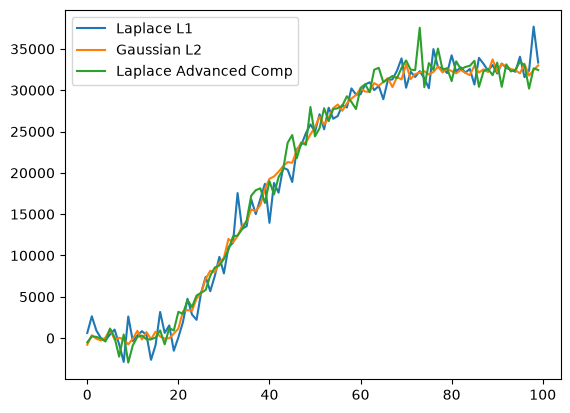

In [ ]:
def age_cdf():
    a = adult['Age']
    return [len(a[a < i]) for i in range(100)]

def laplace_cdf(epsilon):
    return laplace_mech_vec(age_cdf(), 100, epsilon)

def gaussian_cdf(epsilon, delta):
    return gaussian_mech_vec(age_cdf(), np.sqrt(100), epsilon, delta)

def laplace_cdf_advanced_composition(epsilon, delta):
    out = []
    k = len(age_cdf())
    epsilon_i = epsilon / (2 * np.sqrt(2 * k * np.log(1/delta)))
    for v in age_cdf():
        out.append(laplace_mech(v, 1, epsilon_i))
    return out

    # Total priv cost is (100 * ep, 0)-DP 
    # OR epsilon' = (sqrt(2k log(1/delta')) * ep + k * (e^ep - 1))
    # delta = delta

    
    
plt.plot(laplace_cdf(0.1), label='Laplace L1')
plt.plot(gaussian_cdf(0.1, 1e-5), label='Gaussian L2')
plt.plot(laplace_cdf_advanced_composition(0.1, 1e-5), label='Laplace Advanced Comp')
plt.legend();

## Question 1

Consider the retail dataset and the following counting query on it. What is the query's sensitivity?

In [9]:
def retail_query():
    return len(retail[retail['CustomerID'] == 12748])

retail_query()

laplace_mech(retail_query(), sensitivity=1, epsilon=1) # not good, 1 person = many rows

80.69069141267035

The sensitivity is unbounded, it is equal to the max number of orders a person could make, and there is no upper bound on that.

## Question 2

What are we actually protecting in the retail dataset, when the unit of privacy is set to:

1. Event-level / row-level
2. Person-level / user-level

1. We are protecting the privacy of one event (order) - the adversary will not be able to tell whether a person placed some order, but they might be able to tell if that person placed any orders (i.e person is part of dataset?)

2. We are protecting the privacy of one person (all their orders) - the adversary will not be able to tell if the person was present in the dataset, inlcuding if they placed orders or not, order contents, etc.

## Question 3

What is the *effective* person-level $\epsilon$ value for the following query, which assumes a row-level unit of privacy?

In [ ]:
def dp_retail_query():
    result = retail_query()
    # return laplace_mech(result, sensitivity=1, epsilon=1)
    return laplace_mech(result, sensitivity=200, epsilon=1) # Person level epsilon of 1, useless

dp_retail_query()

Let assume each person can make at most 200 orders. to get person level privacy we need to use a sensitivity of 200

We are actually using a sensivity of 1

In laplace: scale of noise is sensitivity/epsilon = 1

If we change sensitivity to 200, we would need an epsilon of 200 to get the same noise scale

Tjos os a huge epsilon and basically a vacuous privacy guarantee

## Question 4

Use *contribution bounding* to adjust the unit of privacy to be person-level privacy, and implement a differentially private function to return the orders originating from the United Kingdom.

In [13]:
def bound_contributions(bound):
    grouped = retail.groupby("CustomerID")
    return grouped.head(bound)
    
def dp_retail_query(bound, epsilon):
    bound_retail = bound_contributions(bound)
    result = len(bound_retail[bound_retail["Country"] == "United Kingdom"])
    return laplace_mech(result, sensitivity=bound, epsilon=epsilon)
    
dp_retail_query(100, 1.0)

6597.587706410896

In [ ]:
# TEST CASE

results = [dp_retail_query(100, 1.0) for _ in range(100)]
errors = [pct_error(len(retail[retail['Country'] == 'United Kingdom']), r) for r in results]
print('mean error:', np.mean(errors))

assert np.mean(errors) > 20
assert np.mean(errors) < 50

## Question 5

Write a function to calculate the L1 **local sensitivity** of the following mean query.

In [ ]:
def mean_query():
    b = 125
    return adult['Age'][adult['Education'] == 'Bachelors'].clip(lower=0, upper=b).mean()

mean_query()

In [ ]:
def mean_query_local_sensitivity():
    # YOUR CODE HERE
    raise NotImplementedError()

mean_query_local_sensitivity()

In [ ]:
# TEST CASE
assert (mean_query_local_sensitivity() - 0.02333831217326363) < 0.0001

## Question 6

Why can't we use the local sensitivity from question 1 directly to achieve differential privacy for `mean_query`?

YOUR ANSWER HERE

## Question 7

Calculate the empirical *cumulative distribution function* of ages in the adult dataset. Use the RDP Gaussian mechanism.

In [ ]:
def calculate_cdf():
    alpha = 5
    epsilon = 0.0001
    
    # YOUR CODE HERE
    raise NotImplementedError()

cdf_vals = calculate_cdf()
plt.plot(range(20, 80), cdf_vals);

## Question 8

What is the *total privacy cost* in RDP of your solution above?

YOUR ANSWER HERE

## Question 9

What is the *total privacy cost* in $(\epsilon, \delta)$-differential privacy of your solution above, for $\delta = 10^{-5}$?

YOUR ANSWER HERE

## Question 10

Repeat the earlier question, but for zero-concentrated differential privacy.

In [ ]:
def gaussian_mech_zCDP(val, sensitivity, rho):
    # YOUR CODE HERE
    raise NotImplementedError()

def calculate_cdf_zcdp():
    rho = 0.00001
    
    # YOUR CODE HERE
    raise NotImplementedError()

cdf_vals = calculate_cdf_zcdp()
plt.plot(range(20, 80), cdf_vals);